,ν = 3,ν = 10,ν = 100
Moyenne,-0.037,-0.109,-0.083
Variance,1.681,1.200,0.953
Asymétrie,0.138,-0.518,0.019
Excès de kurtosis,2.180,0.900,-0.031


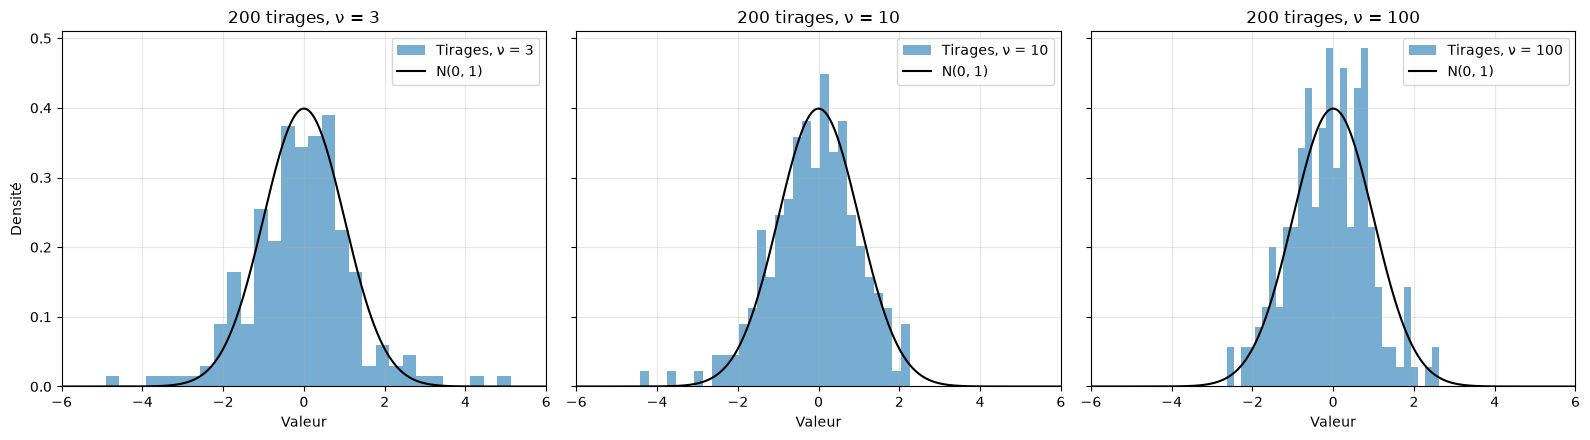

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, skew, kurtosis, t as student_t

def Q3_t(bg, degrees):
    """
    Retourne 200 tirages i.i.d. d'une loi de Student-t à `degrees` degrés de liberté.

    bg      : objet BitGenerator (non "seedé" dans la fonction)
    degrees : entier positif, le nombre de degrés de liberté
    """
    rng = np.random.Generator(bg)          # utilise l'état actuel du BitGenerator
    return rng.standard_t(degrees, size=200)


# Un seul BitGenerator, "seedé" une seule fois, à l'extérieur de la fonction
bg = np.random.PCG64(60321)

liste_degres = [3, 10, 100]
tirages = {nu: Q3_t(bg, nu) for nu in liste_degres}   # même instance pour les trois appels

# Statistiques descriptives de chaque échantillon
stats_q3 = pd.DataFrame({
    f"ν = {nu}": {
        "Moyenne": x.mean(),
        "Variance": x.var(ddof=1),
        "Asymétrie": skew(x),
        "Excès de kurtosis": kurtosis(x),      # kurtosis() de scipy donne déjà l'excès
    }
    for nu, x in tirages.items()
}).round(3)
stats_q3.to_csv("resultats_q3a.csv")
display(stats_q3)

# Histogrammes avec la densité N(0, 1) et la densité de Student-t superposées
grille = np.linspace(-6, 6, 500)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, (nu, x) in zip(axes, tirages.items()):
    ax.hist(x, bins=30, density=True, color="tab:blue", alpha=0.6, label=f"Tirages, ν = {nu}")
    ax.plot(grille, norm.pdf(grille), color="black", linewidth=1.5, label="N(0, 1)")
    ax.set_title(f"200 tirages, ν = {nu}")
    ax.set_xlabel("Valeur")
    ax.set_xlim(-6, 6)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Densité")
plt.tight_layout()
plt.savefig("q3a_histogrammes.png")
plt.show()

In [12]:
import numpy as np

def Q3_Sample(bg, a, r):
    """
    Tire un échantillon de même taille que a.

    bg : objet BitGenerator (non "seedé" dans la fonction)
    a  : tableau 1-D
    r  : True  -> tirage avec remplacement (bootstrap)
         False -> tirage sans remplacement (simple mélange de a)
    """
    rng = np.random.Generator(bg)
    a = np.asarray(a)
    return rng.choice(a, size=a.size, replace=r)


# Démonstration sur un petit exemple : 8 rendements quotidiens fictifs
bg = np.random.PCG64(60321)
a = np.array([-0.05, -0.02, -0.01, 0.00, 0.01, 0.02, 0.03, 0.04])

avec = Q3_Sample(bg, a, True)
sans = Q3_Sample(bg, a, False)

print("Échantillon original     :", a)
print("Avec remplacement        :", avec)
print("Sans remplacement        :", sans)
print()
print(f"Moyenne originale        : {a.mean():.4f}")
print(f"Moyenne avec remplacement: {avec.mean():.4f}")
print(f"Moyenne sans remplacement: {sans.mean():.4f}")
print("Mêmes valeurs que l'original (sans remplacement) ?", np.array_equal(np.sort(sans), np.sort(a)))

Échantillon original     : [-0.05 -0.02 -0.01  0.    0.01  0.02  0.03  0.04]
Avec remplacement        : [ 0.02 -0.01  0.04  0.01 -0.01  0.03  0.04 -0.05]
Sans remplacement        : [-0.01 -0.02 -0.05  0.    0.03  0.02  0.01  0.04]

Moyenne originale        : 0.0025
Moyenne avec remplacement: 0.0088
Moyenne sans remplacement: 0.0025
Mêmes valeurs que l'original (sans remplacement) ? True


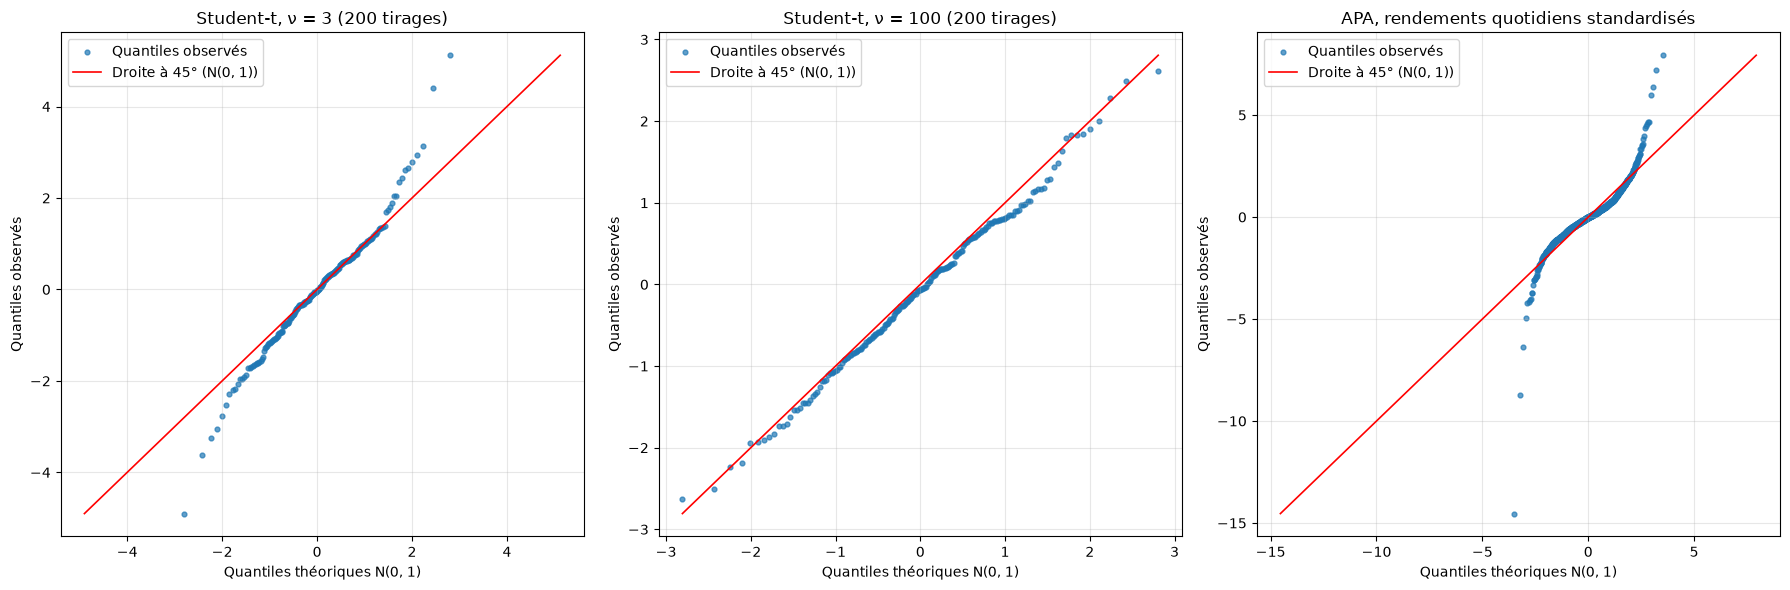

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

def Q3_ProbPlot(s, titre="", ax=None):
    """
    Graphique de probabilité (QQ-plot) comparant les valeurs de s à une loi N(0, 1).

    s     : tableau 1-D
    titre : titre du graphique (optionnel)
    ax    : axe matplotlib où tracer (optionnel)
    """
    s = np.asarray(s, dtype=float)
    s = np.sort(s[~np.isnan(s)])                              # quantiles observés
    n = s.size
    theoriques = norm.ppf((np.arange(1, n + 1) - 0.5) / n)   # quantiles théoriques N(0, 1)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(theoriques, s, s=12, color="tab:blue", alpha=0.7, label="Quantiles observés")
    lim = [min(theoriques.min(), s.min()), max(theoriques.max(), s.max())]
    ax.plot(lim, lim, color="red", linewidth=1.2, label="Droite à 45° (N(0, 1))")
    ax.set_xlabel("Quantiles théoriques N(0, 1)")
    ax.set_ylabel("Quantiles observés")
    ax.set_title(titre)
    ax.grid(alpha=0.3)
    ax.legend()
    return ax


# Rendements d'APA du problème 2, standardisés
rendements = pd.read_csv("rendements_quotidiens.csv", index_col="Date", parse_dates=True)
apa = rendements["APA"].dropna()
apa_std = (apa - apa.mean()) / apa.std()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
Q3_ProbPlot(tirages[3], "Student-t, ν = 3 (200 tirages)", axes[0])
Q3_ProbPlot(tirages[100], "Student-t, ν = 100 (200 tirages)", axes[1])
Q3_ProbPlot(apa_std, "APA, rendements quotidiens standardisés", axes[2])
plt.tight_layout()
plt.savefig("q3c_probplots.png")
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import kstest


def Q3_Sample(bg, a, r):
    """Tire un échantillon de même taille que `a`, avec (r=True) ou sans (r=False) remplacement."""
    rng = np.random.Generator(bg)
    return rng.choice(a, size=len(a), replace=r)


def Q3_KS(bg, a, T):
    """Taux de rejet du test KS (seuil 5 %) sur T échantillons bootstrap standardisés."""
    rejets = 0
    for _ in range(T):
        sample = Q3_Sample(bg, a, True)                                    # bootstrap
        sample_std = (sample - np.mean(sample)) / np.std(sample, ddof=1)   # standardisation
        _, pvalue = kstest(sample_std, "norm")                             # test KS contre N(0, 1)
        if pvalue < 0.05:
            rejets += 1
    return rejets / T


bg_ks = np.random.MT19937(12345)
rng_ks = np.random.Generator(bg_ks)


normal_sample = rng_ks.standard_normal(200)
t3_ks = rng_ks.standard_t(3, 200)

# Données réelles : rendements bruts d'APA
rendements_APA = pd.read_csv("rendements_quotidiens.csv")["APA"].dropna().values

# Taux de rejet
taux = {
    "N(0, 1), 200 tirages (taille)": Q3_KS(bg_ks, normal_sample, 1000),
    "Student-t, ν = 3 (puissance)": Q3_KS(bg_ks, t3_ks, 1000),
    "APA, rendements": Q3_KS(bg_ks, rendements_APA, 1000),
}

tableau_q3d = pd.DataFrame({"Taux de rejet de H0 (5 %)": taux}).round(4)
tableau_q3d.to_excel("resultats_q3d.xlsx", sheet_name="Q3d")
display(tableau_q3d)

,Taux de rejet de H0 (5 %)
"N(0, 1), 200 tirages (taille)",0.057
"Student-t, ν = 3 (puissance)",0.236
"APA, rendements",1.000
